In [ ]:
from pathlib import Path
import zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models , Sequential
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.callbacks import EarlyStopping , ModelCheckpoint , ReduceLROnPlateau



In [8]:
data = np.load("../data/processed/brain_mri_data.npz")

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]



In [ ]:
data_augmentation = Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05 , 0.05)
])

In [ ]:
model = models.Sequential(
    [
        data_augmentation,
        layers.Input(shape=(224, 224, 3)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(128, activation="softmax"),
    ]
)

model.summary()

I0000 00:00:1792164293.237437      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792164293.241039      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,185,472 (42.67 MB)

 Trainable params: 11,185,472 (42.67 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    ),
    ModelCheckpoint(
        "../models/best_model.keras",
        monitor="val_loss",
        save_best_only=True,
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6
    )
] 

In [11]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    validation_data = (X_val , y_val),
    epochs=15,
    batch_size = 32,
    callbacks = callbacks
)


Epoch 1/15


2026-10-16 15:25:06.642002: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 15:25:06.790919: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  2/141 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.0547 - loss: 4.8699     

I0000 00:00:1792164309.790795     144 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4700 - loss: 1.7530

2026-10-16 15:25:18.014945: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 15:25:18.160399: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


141/141 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - accuracy: 0.6017 - loss: 1.1372 - val_accuracy: 0.7794 - val_loss: 0.5492 - learning_rate: 0.0010
Epoch 2/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.7944 - loss: 0.5298 - val_accuracy: 0.8461 - val_loss: 0.3741 - learning_rate: 0.0010
Epoch 3/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.8500 - loss: 0.3889 - val_accuracy: 0.8514 - val_loss: 0.3813 - learning_rate: 0.0010
Epoch 4/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.8965 - loss: 0.2930 - val_accuracy: 0.8772 - val_loss: 0.2972 - learning_rate: 0.0010
Epoch 5/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.9163 - loss: 0.2215 - val_accuracy: 0.9039 - val_loss: 0.2588 - learning_rate: 0.0010
Epoch 6/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - accuracy: 0.9377 - loss: 0.1651 - val_accuracy: 0.9021 - val_loss: 0.2591 - learning_rate: 0.0010
Epoch 7/15
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step - accuracy: 0.9499 - loss: 0.1334 - va

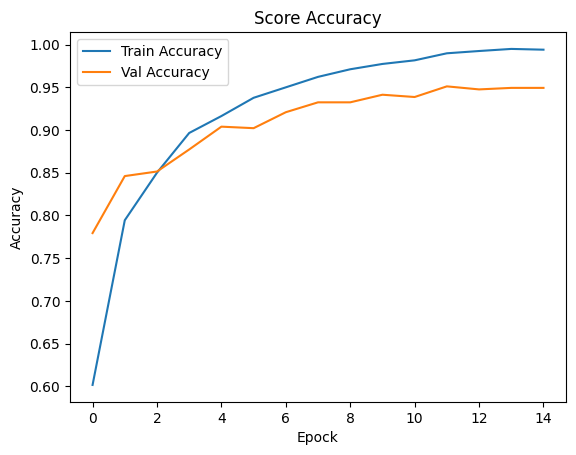

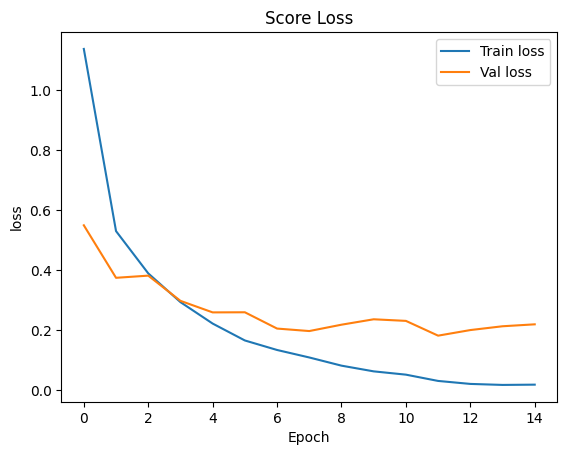

In [12]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure()
plt.plot(accuracy, label='Train Accuracy')
plt.plot(val_accuracy, label='Val Accuracy')
plt.title('Score Accuracy')
plt.xlabel('Epock')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


plt.figure()
plt.plot(loss, label='Train loss')
plt.plot(val_loss, label='Val loss')
plt.title('Score Loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [13]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=42,
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9587 - loss: 0.2334
Test Loss: 0.2334
Test Accuracy: 95.87%


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 718ms/step


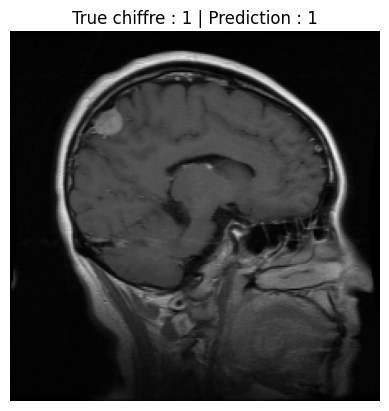

In [14]:
image = X_test[0:1]

probabilities = model.predict(image)[0]

predicted_label = np.argmax(probabilities)
true_label = y_test[0]

plt.imshow(image[0])
plt.title(
    f"True chiffre : {true_label} | Prediction : {predicted_label}"
)
plt.axis("off")
plt.show()

In [15]:
target_names = ["glioma", "meningioma", "notumor", "pituitary"]
y_pred = model.predict(X_test , batch_size=32)
y_pred = np.argmax(y_pred , axis=1)
print(classification_report(
    y_test,
    y_pred,
    target_names=target_names,
))

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step
              precision    recall  f1-score   support

      glioma       0.96      0.96      0.96       324
  meningioma       0.92      0.91      0.92       329
     notumor       0.97      0.98      0.98       400
   pituitary       0.97      0.98      0.98       352

    accuracy                           0.96      1405
   macro avg       0.96      0.96      0.96      1405
weighted avg       0.96      0.96      0.96      1405



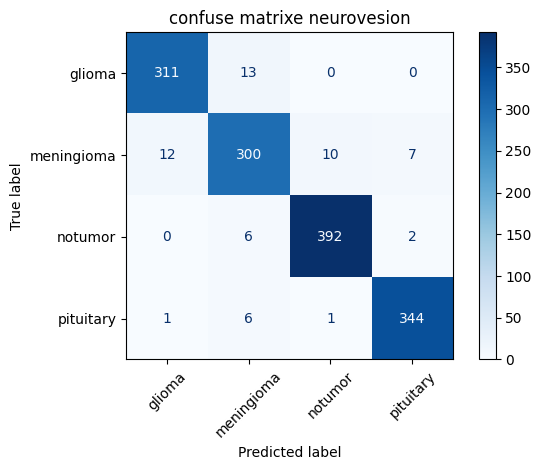

In [16]:
cm = confusion_matrix(y_test , y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels= target_names,
)

display.plot(cmap="Blues" , xticks_rotation=45)
plt.title("confuse matrixe neurovesion")
plt.tight_layout()
plt.show()

In [ ]:
model.save("neurovision_cnn.keras")